In [1]:
from dotenv import load_dotenv

# 加载环境变量
load_dotenv()

True

# Populate the database 填充数据库

- **执行**以下脚本
    - **获取**专门为本教程准备的 SQLite 数据库
    - **更新**数据里的时间，使其看起来像是当前时间。
- 这部分具体细节并不重要。

## 整体运行

In [2]:
import os
import shutil
import sqlite3

import pandas as pd
import requests

# 数据库文件的 URL 地址
db_url = "https://storage.googleapis.com/benchmarks-artifacts/travel-db/travel2.sqlite"
# 本地文件系统的文件名
local_file = "travel2.sqlite"
# 备份文件的名称
backup_file = "travel2.backup.sqlite"
# 是否覆盖已存在的文件
overwrite = False

# 检查本地文件是否存在，如果不存在或设置为覆盖，则从远程 URL 下载数据库文件
if overwrite or not os.path.exists(local_file):
    # 从远程 URL 获取数据库文件。向指定 URL 发送请求并获取响应。
    response = requests.get(db_url)
    # 确认请求成功。如果 HTTP 请求返回了错误状态码，该方法会抛出异常。
    response.raise_for_status()
    # 将响应内容写入本地文件
    with open(local_file, "wb") as f:
        f.write(response.content)
    # 创建一个备份文件，以便在每个教程章节中重置数据库
    shutil.copy(local_file, backup_file)

# 连接到本地数据库文件
conn = sqlite3.connect(local_file)
cursor = conn.cursor()

# 读取数据库中的所有表名
tables = pd.read_sql(
    "SELECT name FROM sqlite_master WHERE type='table';", conn
).name.tolist()

# 创建一个字典来存储所有表的数据
tdf = {}
# 读取数据库中的每个表，并将其存储在字典中，键是表名，值是 Pandas DataFrame 对象
for t in tables:
    tdf[t] = pd.read_sql(f"SELECT * from {t}", conn)

# 计算示例数据中的最大实际出发时间
example_time = pd.to_datetime(
    tdf["flights"]["actual_departure"].replace("\\N", pd.NaT)
).max()

# 获取当前时间，并将其设置为与示例数据相同的时区
current_time = pd.to_datetime("now").tz_localize(example_time.tz)

# 计算当前时间和示例数据之间的时间差
time_diff = current_time - example_time

# 更新 bookings 表中的 book_date 列
tdf["bookings"]["book_date"] = (
    pd.to_datetime(tdf["bookings"]["book_date"].replace("\\N", pd.NaT), utc=True)
    + time_diff
)

# 定义需要更新的日期时间列
datetime_columns = [
    "scheduled_departure",
    "scheduled_arrival",
    "actual_departure",
    "actual_arrival",
]

# 更新 flights 表中的日期时间列
for column in datetime_columns:
    tdf["flights"][column] = (
        pd.to_datetime(tdf["flights"][column].replace("\\N", pd.NaT)) + time_diff
    )

# 将更新后的 DataFrame 写回到数据库中
for table_name, df in tdf.items():
    df.to_sql(table_name, conn, if_exists="replace", index=False)

# 删除临时使用的 df 变量
del df
# 删除整个 tdf 字典
del tdf

# 提交更改到数据库
conn.commit()
# 关闭数据库连接
conn.close()

# 在本教程中我们将使用这个本地文件作为数据库
db = local_file

In [ ]:
# # 如果已有 local_file，不需要运行这一行
# shutil.copy(local_file, backup_file)

# Tools 工具

- **搜索**航空公司的政策手册
- **搜索**和**管理**航班、酒店、汽车租赁和短途旅行的预订

### Lookup Company Policies 查找公司政策

#### 整体运行

In [3]:
import re
import numpy as np
import openai
from langchain_core.tools import tool

# 发起一个GET请求以获取FAQ文本数据
response = requests.get(
    "https://storage.googleapis.com/benchmarks-artifacts/travel-db/swiss_faq.md"
)
response.raise_for_status()  # 如果响应状态不是200，则抛出异常
faq_text = response.text  # 从响应中提取文本数据

# 将FAQ文本分割成多个文档
docs = [{"page_content": txt} for txt in re.split(r"(?=\n##)", faq_text)]


class VectorStoreRetriever:
    def __init__(self, docs: list, vectors: list, oai_client):
        self._arr = np.array(vectors)  # 转换向量列表为NumPy数组
        self._docs = docs  # 存储文档列表
        self._client = oai_client  # 存储OpenAI客户端实例

    @classmethod
    def from_docs(cls, docs, oai_client):
        # 创建文档嵌入向量
        embeddings = oai_client.embeddings.create(
            model="text-embedding-3-small", input=[doc["page_content"] for doc in docs]
        )
        vectors = [emb.embedding for emb in embeddings.data]  # 提取嵌入向量
        return cls(docs, vectors, oai_client)  # 返回VectorStoreRetriever实例

    def query(self, query: str, k: int = 5) -> list[dict]:
        # 创建查询字符串的嵌入向量
        embed = self._client.embeddings.create(
            model="text-embedding-3-small", input=[query]
        )
        # 计算查询向量与所有文档向量之间的相似度分数
        scores = np.array(embed.data[0].embedding) @ self._arr.T
        # 获取相似度最高的前k个文档的索引
        top_k_idx = np.argpartition(scores, -k)[-k:]
        # 按照相似度分数从高到低排序这些索引
        top_k_idx_sorted = top_k_idx[np.argsort(-scores[top_k_idx])]
        # 返回最相关的文档及其相似度分数
        return [
            {**self._docs[idx], "similarity": scores[idx]} for idx in top_k_idx_sorted
        ]


# 根据文档创建向量存储检索器
retriever = VectorStoreRetriever.from_docs(docs, openai.Client())


@tool
def lookup_policy(query: str) -> str:
    """查询公司政策以检查某些选项是否被允许。
    在进行任何航班更改或其他'写'操作之前使用此功能。"""
    # 查询最相关的文档
    docs = retriever.query(query, k=2)
    # 将相关文档的内容合并成一个字符串并返回
    return "\n\n".join([doc["page_content"] for doc in docs])

### Flights 航班

- fetch_user_flight_information()
    - 查询用户的所有机票及其对应的航班信息和座位分配。
- search_flights()
    - 根据出发机场、到达机场和出发时间范围搜索航班。
- update_ticket_to_new_flight()
    - 更新用户的机票到一个新的有效航班上。
- cancel_ticket()
    - 取消用户的机票并从数据库中删除。


涉及到的数据表：

- ticket_flights 
- flights
- boarding_passes
- tickets 


我们使用ensure_config通过可配置参数传入passenger_id 。LLM永远不必显式提供这些，它们是为图的给定调用而提供的，以便每个用户无法访问其他乘客的预订信息。

In [4]:
import sqlite3
from datetime import date, datetime
from typing import Optional

import pytz
from langchain_core.runnables import ensure_config


@tool
def fetch_user_flight_information() -> list[dict]:
    """查询用户的所有机票及其对应的航班信息和座位分配。

    返回:
        一个字典列表，其中每个字典包含用户的机票详情、关联的航班详情以及每张机票的座位分配。
    """
    config = ensure_config()  # 从上下文中获取配置
    configuration = config.get("configurable", {})
    passenger_id = configuration.get("passenger_id", None)
    if not passenger_id:
        raise ValueError("未配置乘客ID。")

    conn = sqlite3.connect(db)
    cursor = conn.cursor()

    query = """
    SELECT 
        t.ticket_no, t.book_ref,
        f.flight_id, f.flight_no, f.departure_airport, f.arrival_airport, f.scheduled_departure, f.scheduled_arrival,
        bp.seat_no, tf.fare_conditions
    FROM 
        tickets t
        JOIN ticket_flights tf ON t.ticket_no = tf.ticket_no
        JOIN flights f ON tf.flight_id = f.flight_id
        JOIN boarding_passes bp ON bp.ticket_no = t.ticket_no AND bp.flight_id = f.flight_id
    WHERE 
        t.passenger_id = ?
    """
    cursor.execute(query, (passenger_id,))
    rows = cursor.fetchall()
    column_names = [column[0] for column in cursor.description]
    results = [dict(zip(column_names, row)) for row in rows]

    cursor.close()
    conn.close()

    return results


@tool
def search_flights(
    departure_airport: Optional[str] = None,
    arrival_airport: Optional[str] = None,
    start_time: Optional[date | datetime] = None,
    end_time: Optional[date | datetime] = None,
    limit: int = 20,
) -> list[dict]:
    """根据出发机场、到达机场和出发时间范围搜索航班。

    参数:
        departure_airport: 出发机场代码。
        arrival_airport: 到达机场代码。
        start_time: 起始时间（日期或具体时间）。
        end_time: 结束时间（日期或具体时间）。
        limit: 返回结果的最大数量，默认为20。
    """
    conn = sqlite3.connect(db)
    cursor = conn.cursor()

    query = "SELECT * FROM flights WHERE 1 = 1"
    params = []

    if departure_airport:
        query += " AND departure_airport = ?"
        params.append(departure_airport)

    if arrival_airport:
        query += " AND arrival_airport = ?"
        params.append(arrival_airport)

    if start_time:
        query += " AND scheduled_departure >= ?"
        params.append(start_time)

    if end_time:
        query += " AND scheduled_departure <= ?"
        params.append(end_time)
    query += " LIMIT ?"
    params.append(limit)
    cursor.execute(query, params)
    rows = cursor.fetchall()
    column_names = [column[0] for column in cursor.description]
    results = [dict(zip(column_names, row)) for row in rows]

    cursor.close()
    conn.close()

    return results


@tool
def update_ticket_to_new_flight(ticket_no: str, new_flight_id: int) -> str:
    """更新用户的机票到一个新的有效航班上。

    参数:
        ticket_no: 机票号。
        new_flight_id: 新航班ID。
    """
    config = ensure_config()
    configuration = config.get("configurable", {})
    passenger_id = configuration.get("passenger_id", None)
    if not passenger_id:
        raise ValueError("未配置乘客ID。")

    conn = sqlite3.connect(db)
    cursor = conn.cursor()

    cursor.execute(
        "SELECT departure_airport, arrival_airport, scheduled_departure FROM flights WHERE flight_id = ?",
        (new_flight_id,),
    )
    new_flight = cursor.fetchone()
    if not new_flight:
        cursor.close()
        conn.close()
        return "提供的新航班ID无效。"
    column_names = [column[0] for column in cursor.description]
    new_flight_dict = dict(zip(column_names, new_flight))
    timezone = pytz.timezone("Etc/GMT-3")
    current_time = datetime.now(tz=timezone)
    departure_time = datetime.strptime(
        new_flight_dict["scheduled_departure"], "%Y-%m-%d %H:%M:%S.%f%z"
    )
    time_until = (departure_time - current_time).total_seconds()
    if time_until < (3 * 3600):
        return f"不允许重新安排在距当前时间少于3小时内的航班。所选航班时间为 {departure_time}。"

    cursor.execute(
        "SELECT flight_id FROM ticket_flights WHERE ticket_no = ?", (ticket_no,)
    )
    current_flight = cursor.fetchone()
    if not current_flight:
        cursor.close()
        conn.close()
        return "没有找到给定机票号对应的现有机票。"

    # 检查已登录的用户是否确实拥有这张机票
    cursor.execute(
        "SELECT * FROM tickets WHERE ticket_no = ? AND passenger_id = ?",
        (ticket_no, passenger_id),
    )
    current_ticket = cursor.fetchone()
    if not current_ticket:
        cursor.close()
        conn.close()
        return f"当前登录乘客ID {passenger_id} 不是机票 {ticket_no} 的所有者"

    # 在实际应用中，你可能还需要添加额外的检查来执行业务逻辑，
    # 比如“新的出发机场是否与当前机票匹配”等。
    # 尽管最好尝试对语言模型进行“类型提示”，以使其了解策略，
    # 但不可避免地会出现错误，因此你也需要确保你的API能够强制有效的行为。
    cursor.execute(
        "UPDATE ticket_flights SET flight_id = ? WHERE ticket_no = ?",
        (new_flight_id, ticket_no),
    )
    conn.commit()

    cursor.close()
    conn.close()
    return "机票成功更新至新的航班。"


@tool
def cancel_ticket(ticket_no: str) -> str:
    """取消用户的机票并从数据库中删除。

    参数:
        ticket_no: 机票号。
    """
    config = ensure_config()
    configuration = config.get("configurable", {})
    passenger_id = configuration.get("passenger_id", None)
    if not passenger_id:
        raise ValueError("未配置乘客ID。")
    conn = sqlite3.connect(db)
    cursor = conn.cursor()

    cursor.execute(
        "SELECT flight_id FROM ticket_flights WHERE ticket_no = ?", (ticket_no,)
    )
    existing_ticket = cursor.fetchone()
    if not existing_ticket:
        cursor.close()
        conn.close()
        return "没有找到给定机票号对应的现有机票。"

    # 检查已登录的用户是否确实拥有这张机票
    cursor.execute(
        "SELECT flight_id FROM tickets WHERE ticket_no = ? AND passenger_id = ?",
        (ticket_no, passenger_id),
    )
    current_ticket = cursor.fetchone()
    if not current_ticket:
        cursor.close()
        conn.close()
        return f"当前登录乘客ID {passenger_id} 不是机票 {ticket_no} 的所有者"

    cursor.execute("DELETE FROM ticket_flights WHERE ticket_no = ?", (ticket_no,))
    conn.commit()

    cursor.close()
    conn.close()
    return "机票成功取消。"

### Car Rental Tools 租车工具

定义一些工具，让用户能够在目的地**搜索**和**预订**汽车。

- search_car_rentals()
    - 根据地点、名称、价格等级、开始日期和结束日期搜索汽车租赁信息。
- book_car_rental()
    - 通过其ID预订汽车租赁服务。
- update_car_rental()
    - 通过其ID更新汽车租赁服务的开始日期和结束日期。
- cancel_car_rental()
    - 通过其ID取消汽车租赁服务。

涉及到的数据表：

- car_rentals

In [5]:
from datetime import date, datetime
from typing import Optional, Union
import sqlite3


@tool
def search_car_rentals(
    location: Optional[str] = None,
    name: Optional[str] = None,
    price_tier: Optional[str] = None,
    start_date: Optional[Union[datetime, date]] = None,
    end_date: Optional[Union[datetime, date]] = None,
) -> list[dict]:
    """
    根据地点、名称、价格等级、开始日期和结束日期搜索汽车租赁信息。

    参数:
        location (Optional[str]): 汽车租赁的地点。默认为 None。
        name (Optional[str]): 汽车租赁公司的名称。默认为 None。
        price_tier (Optional[str]): 汽车租赁的价格等级。默认为 None。
        start_date (Optional[Union[datetime, date]]): 汽车租赁的开始日期。默认为 None。
        end_date (Optional[Union[datetime, date]]): 汽车租赁的结束日期。默认为 None。

    返回:
        list[dict]: 符合搜索条件的汽车租赁字典列表。
    """
    conn = sqlite3.connect(db)
    cursor = conn.cursor()

    query = "SELECT * FROM car_rentals WHERE 1=1"
    params = []

    if location:
        query += " AND location LIKE ?"
        params.append(f"%{location}%")
    if name:
        query += " AND name LIKE ?"
        params.append(f"%{name}%")
    # 在我们的教程中，我们将让你匹配任何日期和价格等级
    # （因为我们使用的示例数据集没有太多数据）
    cursor.execute(query, params)
    results = cursor.fetchall()

    conn.close()

    return [
        dict(zip([column[0] for column in cursor.description], row)) for row in results
    ]


@tool
def book_car_rental(rental_id: int) -> str:
    """
    通过其ID预订汽车租赁服务。

    参数:
        rental_id (int): 需要预订的汽车租赁服务的ID。

    返回:
        str: 表示汽车租赁是否成功预订的消息。
    """
    conn = sqlite3.connect(db)
    cursor = conn.cursor()

    cursor.execute("UPDATE car_rentals SET booked = 1 WHERE id = ?", (rental_id,))
    conn.commit()

    if cursor.rowcount > 0:
        conn.close()
        return f"汽车租赁 {rental_id} 成功预订。"
    else:
        conn.close()
        return f"未找到ID为 {rental_id} 的汽车租赁服务。"


@tool
def update_car_rental(
    rental_id: int,
    start_date: Optional[Union[datetime, date]] = None,
    end_date: Optional[Union[datetime, date]] = None,
) -> str:
    """
    通过其ID更新汽车租赁服务的开始日期和结束日期。

    参数:
        rental_id (int): 需要更新的汽车租赁服务的ID。
        start_date (Optional[Union[datetime, date]]): 汽车租赁的新开始日期。默认为 None。
        end_date (Optional[Union[datetime, date]]): 汽车租赁的新结束日期。默认为 None。

    返回:
        str: 表示汽车租赁是否成功更新的消息。
    """
    conn = sqlite3.connect(db)
    cursor = conn.cursor()

    if start_date:
        cursor.execute(
            "UPDATE car_rentals SET start_date = ? WHERE id = ?",
            (start_date, rental_id),
        )
    if end_date:
        cursor.execute(
            "UPDATE car_rentals SET end_date = ? WHERE id = ?", (end_date, rental_id)
        )

    conn.commit()

    if cursor.rowcount > 0:
        conn.close()
        return f"汽车租赁 {rental_id} 成功更新。"
    else:
        conn.close()
        return f"未找到ID为 {rental_id} 的汽车租赁服务。"


@tool
def cancel_car_rental(rental_id: int) -> str:
    """
    通过其ID取消汽车租赁服务。

    参数:
        rental_id (int): 需要取消的汽车租赁服务的ID。

    返回:
        str: 表示汽车租赁是否成功取消的消息。
    """
    conn = sqlite3.connect(db)
    cursor = conn.cursor()

    cursor.execute("UPDATE car_rentals SET booked = 0 WHERE id = ?", (rental_id,))
    conn.commit()

    if cursor.rowcount > 0:
        conn.close()
        return f"汽车租赁 {rental_id} 成功取消。"
    else:
        conn.close()
        return f"未找到ID为 {rental_id} 的汽车租赁服务。"

### Hotels 酒店

定义一些工具，让用户能够在目的地**搜索**和**管理**酒店预订。

- search_hotels()
    - 根据位置、名称、价格等级、入住日期和退房日期搜索酒店。
- book_hotel()
    - 通过其ID预订酒店。
- update_hotel()
    - 通过其ID更新酒店的入住和退房日期。
- cancel_hotel()
    - 通过其ID取消酒店预订。

涉及到的数据表：

- hotels

In [6]:
@tool
def search_hotels(
    location: Optional[str] = None,
    name: Optional[str] = None,
    price_tier: Optional[str] = None,
    checkin_date: Optional[Union[datetime, date]] = None,
    checkout_date: Optional[Union[datetime, date]] = None,
) -> list[dict]:
    """
    根据位置、名称、价格等级、入住日期和退房日期搜索酒店。

    参数:
        location (Optional[str]): 酒店的位置。默认为 None。
        name (Optional[str]): 酒店的名称。默认为 None。
        price_tier (Optional[str]): 酒店的价格等级。默认为 None。示例：中档，高档，豪华
        checkin_date (Optional[Union[datetime, date]]): 酒店的入住日期。默认为 None。
        checkout_date (Optional[Union[datetime, date]]): 酒店的退房日期。默认为 None。

    返回:
        list[dict]: 符合搜索条件的酒店字典列表。
    """
    conn = sqlite3.connect(db)
    cursor = conn.cursor()

    query = "SELECT * FROM hotels WHERE 1=1"
    params = []

    if location:
        query += " AND location LIKE ?"
        params.append(f"%{location}%")
    if name:
        query += " AND name LIKE ?"
        params.append(f"%{name}%")
    # 为了本教程的目的，我们将允许你匹配任何日期和价格等级。
    cursor.execute(query, params)
    results = cursor.fetchall()

    conn.close()

    return [
        dict(zip([column[0] for column in cursor.description], row)) for row in results
    ]


@tool
def book_hotel(hotel_id: int) -> str:
    """
    通过其ID预订酒店。

    参数:
        hotel_id (int): 要预订的酒店的ID。

    返回:
        str: 指示酒店是否成功预订的消息。
    """
    conn = sqlite3.connect(db)
    cursor = conn.cursor()

    cursor.execute("UPDATE hotels SET booked = 1 WHERE id = ?", (hotel_id,))
    conn.commit()

    if cursor.rowcount > 0:
        conn.close()
        return f"酒店 {hotel_id} 成功预订。"
    else:
        conn.close()
        return f"未找到ID为 {hotel_id} 的酒店。"


@tool
def update_hotel(
    hotel_id: int,
    checkin_date: Optional[Union[datetime, date]] = None,
    checkout_date: Optional[Union[datetime, date]] = None,
) -> str:
    """
    通过其ID更新酒店的入住和退房日期。

    参数:
        hotel_id (int): 要更新的酒店的ID。
        checkin_date (Optional[Union[datetime, date]]): 酒店的新入住日期。默认为 None。
        checkout_date (Optional[Union[datetime, date]]): 酒店的新退房日期。默认为 None。

    返回:
        str: 指示酒店是否成功更新的消息。
    """
    conn = sqlite3.connect(db)
    cursor = conn.cursor()

    if checkin_date:
        cursor.execute(
            "UPDATE hotels SET checkin_date = ? WHERE id = ?", (checkin_date, hotel_id)
        )
    if checkout_date:
        cursor.execute(
            "UPDATE hotels SET checkout_date = ? WHERE id = ?",
            (checkout_date, hotel_id),
        )

    conn.commit()

    if cursor.rowcount > 0:
        conn.close()
        return f"酒店 {hotel_id} 成功更新。"
    else:
        conn.close()
        return f"未找到ID为 {hotel_id} 的酒店。"


@tool
def cancel_hotel(hotel_id: int) -> str:
    """
    通过其ID取消酒店预订。

    参数:
        hotel_id (int): 要取消的酒店的ID。

    返回:
        str: 指示酒店是否成功取消的消息。
    """
    conn = sqlite3.connect(db)
    cursor = conn.cursor()

    cursor.execute("UPDATE hotels SET booked = 0 WHERE id = ?", (hotel_id,))
    conn.commit()

    if cursor.rowcount > 0:
        conn.close()
        return f"酒店 {hotel_id} 成功取消。"
    else:
        conn.close()
        return f"未找到ID为 {hotel_id} 的酒店。"

### Excursions 短途旅行

定义一些工具，让用户在到达目的地后**搜索**活动并**预订**。

- search_trip_recommendations()
    - 根据地点、名称和关键词搜索旅行推荐信息。
- book_excursion()
    - 通过其推荐ID预订一次游览活动。
- update_excursion()
    - 通过其ID更新旅行推荐信息的详情。
- cancel_excursion()
    - 通过其ID取消旅行推荐信息。

涉及到的数据表：

- trip_recommendations

In [7]:
@tool
def search_trip_recommendations(
    location: Optional[str] = None,
    name: Optional[str] = None,
    keywords: Optional[str] = None,
) -> list[dict]:
    """
    根据地点、名称和关键词搜索旅行推荐信息。

    参数:
        location (Optional[str]): 旅行推荐信息的地点。默认为 None。
        name (Optional[str]): 旅行推荐信息的名称。默认为 None。
        keywords (Optional[str]): 与旅行推荐信息相关的关键词。默认为 None。

    返回:
        list[dict]: 符合搜索条件的旅行推荐信息字典列表。
    """
    conn = sqlite3.connect(db)
    cursor = conn.cursor()

    query = "SELECT * FROM trip_recommendations WHERE 1=1"
    params = []

    if location:
        query += " AND location LIKE ?"
        params.append(f"%{location}%")
    if name:
        query += " AND name LIKE ?"
        params.append(f"%{name}%")
    if keywords:
        keyword_list = keywords.split(",")
        keyword_conditions = " OR ".join(["keywords LIKE ?" for _ in keyword_list])
        query += f" AND ({keyword_conditions})"
        params.extend([f"%{keyword.strip()}%" for keyword in keyword_list])

    cursor.execute(query, params)
    results = cursor.fetchall()

    conn.close()

    return [
        dict(zip([column[0] for column in cursor.description], row)) for row in results
    ]


@tool
def book_excursion(recommendation_id: int) -> str:
    """
    通过其推荐ID预订一次游览活动。

    参数:
        recommendation_id (int): 要预订的旅行推荐信息的ID。

    返回:
        str: 指示旅行推荐信息是否成功预订的消息。
    """
    conn = sqlite3.connect(db)
    cursor = conn.cursor()

    cursor.execute(
        "UPDATE trip_recommendations SET booked = 1 WHERE id = ?", (recommendation_id,)
    )
    conn.commit()

    if cursor.rowcount > 0:
        conn.close()
        return f"旅行推荐信息 {recommendation_id} 预订成功。"
    else:
        conn.close()
        return f"未找到ID为 {recommendation_id} 的旅行推荐信息。"


@tool
def update_excursion(recommendation_id: int, details: str) -> str:
    """
    通过其ID更新旅行推荐信息的详情。

    参数:
        recommendation_id (int): 要更新的旅行推荐信息的ID。
        details (str): 旅行推荐信息的新详情。

    返回:
        str: 指示旅行推荐信息是否成功更新的消息。
    """
    conn = sqlite3.connect(db)
    cursor = conn.cursor()

    cursor.execute(
        "UPDATE trip_recommendations SET details = ? WHERE id = ?",
        (details, recommendation_id),
    )
    conn.commit()

    if cursor.rowcount > 0:
        conn.close()
        return f"旅行推荐信息 {recommendation_id} 更新成功。"
    else:
        conn.close()
        return f"未找到ID为 {recommendation_id} 的旅行推荐信息。"


@tool
def cancel_excursion(recommendation_id: int) -> str:
    """
    通过其ID取消旅行推荐信息。

    参数:
        recommendation_id (int): 要取消的旅行推荐信息的ID。

    返回:
        str: 指示旅行推荐信息是否成功取消的消息。
    """
    conn = sqlite3.connect(db)
    cursor = conn.cursor()

    cursor.execute(
        "UPDATE trip_recommendations SET booked = 0 WHERE id = ?", (recommendation_id,)
    )
    conn.commit()

    if cursor.rowcount > 0:
        conn.close()
        return f"旅行推荐信息 {recommendation_id} 取消成功。"
    else:
        conn.close()
        return f"未找到ID为 {recommendation_id} 的旅行推荐信息。"

### Utilities 实用工具

定义一些辅助函数，以便在我们调试图时**漂亮地打印**图中的消息，并为我们的工具节点**提供**错误处理（通过将错误添加到聊天历史记录中）。

- handle_tool_error()
    - 处理工具错误，并返回带有错误信息的消息
- create_tool_node_with_fallback()
    - 创建一个带有错误回退处理的工具节点
- _print_event()
    - 打印事件信息，包括当前对话状态和消息

In [8]:
from langchain_core.messages import ToolMessage
from langchain_core.runnables import RunnableLambda

from langgraph.prebuilt import ToolNode


# 处理工具错误，并返回带有错误信息的消息
def handle_tool_error(state) -> dict:
    error = state.get("error")
    tool_calls = state["messages"][-1].tool_calls
    return {
        "messages": [
            ToolMessage(
                content=f"错误: {repr(error)}\n 请修正您的错误。",
                tool_call_id=tc["id"],
            )
            for tc in tool_calls
        ]
    }


# 创建一个带有错误回退处理的工具节点
def create_tool_node_with_fallback(tools: list) -> dict:
    return ToolNode(tools).with_fallbacks(
        [RunnableLambda(handle_tool_error)], exception_key="error"
    )


# 打印事件信息，包括当前对话状态和消息
def _print_event(event: dict, _printed: set, max_length=1500):
    current_state = event.get("dialog_state")
    if current_state:
        print("当前处于: ", current_state[-1])
    message = event.get("messages")
    if message:
        if isinstance(message, list):
            message = message[-1]
        if message.id not in _printed:
            msg_repr = message.pretty_repr(html=True)
            if len(msg_repr) > max_length:
                msg_repr = msg_repr[:max_length] + " ... (已截断)"
            print(msg_repr)
            _printed.add(message.id)

# Part 3: Conditional Interrupt 条件中断

在本节中，我们将通过将工具**分类**为安全（只读）或敏感（数据修改）来**完善**中断策略。我们将**仅**对敏感工具**应用中断**，从而允许机器人自主处理简单的查询。

这**平衡**了用户控制和对话流，但是随着我们添加更多工具，我们的单个图对于这种“扁平”结构可能变得过于复杂。我们将在下一节中解决这个问题。

![Part 3 Diagram](assets/part-3-diagram.png)

# Part 4: Specialized Workflows 专业工作流程

第3部分设计的一个问题是我们对单个提示施加了很大的压力。如果我们想添加更多工具，或者每个工具变得更加复杂（更多过滤器、更多业务逻辑约束行为等），那么工具的使用和机器人的整体行为可能会开始受到影响。

在本节中，我们将学习如何通过**根据**用户意图**路由**到专家智能体或子图来**更好地控制**不同的用户体验。

在本节中，我们将把用户体验分成单独的子图，形成如下结构：

![Part 4 Diagram](assets/part-4-diagram.png)

在上图中，每个方块都包含一个智能的、集中的工作流程。主要助理负责处理用户的初始查询，图根据查询内容路由到适当的“专家”。

### State

- 我们希望在任何给定时刻跟踪哪个子图处于控制状态。
- 所以新增`dialog_state`字段，`list`类型。
- `dialog_state`字段使用栈（Stack）这种数据结构来跟踪。
    - 每当`node`运行并返回`dialog_state`的值时，都会调用`update_dialog_stack`函数来确定如何应用更新。

> 栈（Stack）是一种数据结构，它遵循后进先出（LIFO, Last In First Out）的原则。这意味着最后被添加到栈中的元素最先被移除。
>
> 栈有两个主要操作：
> 
> 压栈（Push）：将一个元素添加到栈的顶部。
> 
> 弹栈（Pop）：从栈的顶部移除一个元素。

In [9]:
from typing import Annotated, Literal, Optional

from typing_extensions import TypedDict

from langgraph.graph.message import AnyMessage, add_messages


def update_dialog_stack(left: list[str], right: Optional[str]) -> list[str]:
    """推入或弹出状态。"""
    # left：表示当前的对话状态栈。
    # right：表示需要推入栈的状态或者是 pop 操作。
    
    # 没有操作要进行，直接返回当前栈 
    if right is None:
        return left
    # 需要弹出栈顶元素，返回去掉最后一个元素后的列表。
    if right == "pop":
        return left[:-1]
    # 其他情况，将 right 添加到 left 列表的末尾，返回新的列表。
    return left + [right]


class State(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]
    user_info: str
    dialog_state: Annotated[
        list[
            Literal[
                "assistant",
                "update_flight",
                "book_car_rental",
                "book_hotel",
                "book_excursion",
            ]
        ],
        update_dialog_stack,
    ]

### Assistant

这次我们将为每个工作流程创建一个助手。

specialized / delegated assistant
Flight booking assistant 机票预订助理
Hotel booking assistant 酒店预订助理
Car rental assistant 租车助理
Excursion assistant 游览助理

primary assistant
and finally, a "primary assistant" to route between these
最后，一个“主要助手”在这些之间进行路由

#### Assistant

In [10]:
from langchain_openai import ChatOpenAI
from langchain_community.tools import DuckDuckGoSearchResults
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import Runnable, RunnableConfig


class Assistant:
    def __init__(self, runnable: Runnable):
        self.runnable = runnable

    def __call__(self, state: State, config: RunnableConfig):
        while True:
            result = self.runnable.invoke(state)
            if not result.tool_calls and (
                not result.content
                or isinstance(result.content, list)
                and not result.content[0].get("text")
            ):
                messages = state["messages"] + [("user", "请给出真实的输出。")]
                state = {**state, "messages": messages}
            else:
                break
        return {"messages": result}

#### CompleteOrEscalate

每个专业助理还可以调用`CompleteOrEscalate`工具来指示控制流应传递回主要助理。

In [11]:
from langchain_core.pydantic_v1 import BaseModel, Field


class CompleteOrEscalate(BaseModel):
    """一个工具，用于标记当前任务已完成和/或将对话控制权升级给主助手，
    主助手可以根据用户的需求重新引导对话。"""

    cancel: bool = True
    reason: str

    class Config:
        schema_extra = {
            "example": {
                "cancel": True,
                "reason": "用户改变了对当前任务的想法。",
            },
            "example 2": {
                "cancel": True,
                "reason": "我已完全完成任务。",
            },
            "example 3": {
                "cancel": False,
                "reason": "我需要搜索用户的电子邮件或日历以获取更多信息。",
            },
        }

In [12]:
llm = ChatOpenAI(model="gpt-4-turbo")

#### 航班预订助手

In [13]:
# Flight booking assistant
# 航班预订助手

flight_booking_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "您是一个专门处理航班更新的助手。"
            "主助手在用户需要帮助更新预订时将工作委派给您。"
            "请与客户确认更新后的航班详情，并告知他们任何额外费用。"
            "在搜索时，请保持耐心。如果第一次搜索没有结果，请扩大查询范围。"
            "如果您需要更多信息或客户改变了主意，请将任务升级给主助手。"
            "记住，预订在相关工具成功使用后才算完成。"
            "\n\n当前用户航班信息：\n<Flights>\n{user_info}\n</Flights>"
            "\n当前时间：{time}。"
            "\n\n如果用户需要帮助，并且您的工具都不适用，则"
            '将对话 "CompleteOrEscalate" 升级给主助手。不要浪费用户的时间。不要编造无效的工具或功能。',
        ),
        ("placeholder", "{messages}"),
    ]
).partial(time=datetime.now())

# 安全的航班更新工具
update_flight_safe_tools = [search_flights]
# 敏感的航班更新工具
update_flight_sensitive_tools = [update_ticket_to_new_flight, cancel_ticket]
# 所有航班更新工具
update_flight_tools = update_flight_safe_tools + update_flight_sensitive_tools
# 航班更新任务流
update_flight_runnable = flight_booking_prompt | llm.bind_tools(
    update_flight_tools + [CompleteOrEscalate]
)

#### 酒店预订助手

In [14]:
# Hotel Booking Assistant
# 酒店预订助手

book_hotel_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "您是一个专门处理酒店预订的助手。"
            "主助手在用户需要帮助预订酒店时将工作委派给您。"
            "根据用户的偏好搜索可用的酒店，并与客户确认预订详情。"
            "在搜索时，请保持耐心。如果第一次搜索没有结果，请扩大查询范围。"
            "如果您需要更多信息或客户改变了主意，请将任务升级给主助手。"
            "记住，预订在相关工具成功使用后才算完成。"
            "\n当前时间：{time}。"
            '\n\n如果用户需要帮助，并且您的工具都不适用，则将对话 "CompleteOrEscalate" 升级给主助手。'
            "不要浪费用户的时间。不要编造无效的工具或功能。"
            "\n\n以下是您应该 CompleteOrEscalate 的一些示例：\n"
            " - '这个季节的天气怎么样？'\n"
            " - '算了，我想我会单独预订'\n"
            " - '我需要在那里的交通工具安排'\n"
            " - '哦等等，我还没订机票，我先订机票'\n"
            " - '酒店预订确认'",
        ),
        ("placeholder", "{messages}"),
    ]
).partial(time=datetime.now())

# 安全的酒店预订工具
book_hotel_safe_tools = [search_hotels]
# 敏感的酒店预订工具
book_hotel_sensitive_tools = [book_hotel, update_hotel, cancel_hotel]
# 所有酒店预订工具
book_hotel_tools = book_hotel_safe_tools + book_hotel_sensitive_tools
# 酒店预订任务流
book_hotel_runnable = book_hotel_prompt | llm.bind_tools(
    book_hotel_tools + [CompleteOrEscalate]
)

#### 汽车租赁助手

In [15]:
# Car Rental Assistant
# 汽车租赁助手

book_car_rental_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "您是一个专门处理汽车租赁预订的助手。"
            "主助手在用户需要帮助预订汽车租赁时将工作委派给您。"
            "根据用户的偏好搜索可用的汽车租赁，并与客户确认预订详情。"
            "在搜索时，请保持耐心。如果第一次搜索没有结果，请扩大查询范围。"
            "如果您需要更多信息或客户改变了主意，请将任务升级给主助手。"
            "记住，预订在相关工具成功使用后才算完成。"
            "\n当前时间：{time}。"
            "\n\n如果用户需要帮助，并且您的工具都不适用，则将对话 "
            '"CompleteOrEscalate" 升级给主助手。不要浪费用户的时间。不要编造无效的工具或功能。'
            "\n\n以下是您应该 CompleteOrEscalate 的一些示例：\n"
            " - '这个季节的天气怎么样？'\n"
            " - '有哪些航班可用？'\n"
            " - '算了，我想我会单独预订'\n"
            " - '哦等等，我还没订机票，我先订机票'\n"
            " - '汽车租赁预订确认'",
        ),
        ("placeholder", "{messages}"),
    ]
).partial(time=datetime.now())

# 安全的汽车租赁工具
book_car_rental_safe_tools = [search_car_rentals]
# 敏感的汽车租赁工具
book_car_rental_sensitive_tools = [
    book_car_rental,
    update_car_rental,
    cancel_car_rental,
]
# 所有汽车租赁工具
book_car_rental_tools = book_car_rental_safe_tools + book_car_rental_sensitive_tools
# 汽车租赁任务流
book_car_rental_runnable = book_car_rental_prompt | llm.bind_tools(
    book_car_rental_tools + [CompleteOrEscalate]
)

#### 旅行推荐助手

In [16]:
# Excursion Assistant
# 旅行推荐助手

book_excursion_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "您是一个专门处理行程推荐的助手。"
            "主助手在用户需要帮助预订推荐行程时将工作委派给您。"
            "根据用户的偏好搜索可用的行程推荐，并与客户确认预订详情。"
            "如果您需要更多信息或客户改变了主意，请将任务升级给主助手。"
            "在搜索时，请保持耐心。如果第一次搜索没有结果，请扩大查询范围。"
            "记住，预订在相关工具成功使用后才算完成。"
            "\n当前时间：{time}。"
            '\n\n如果用户需要帮助，并且您的工具都不适用，则将对话 "CompleteOrEscalate" 升级给主助手。不要浪费用户的时间。不要编造无效的工具或功能。'
            "\n\n以下是您应该 CompleteOrEscalate 的一些示例：\n"
            " - '算了，我想我会单独预订'\n"
            " - '我需要在那里的交通工具安排'\n"
            " - '哦等等，我还没订机票，我先订机票'\n"
            " - '游览预订确认!'",
        ),
        ("placeholder", "{messages}"),
    ]
).partial(time=datetime.now())

# 安全的游览预订工具
book_excursion_safe_tools = [search_trip_recommendations]
# 敏感的游览预订工具
book_excursion_sensitive_tools = [book_excursion, update_excursion, cancel_excursion]
# 所有游览预订工具
book_excursion_tools = book_excursion_safe_tools + book_excursion_sensitive_tools
# 游览预订任务流
book_excursion_runnable = book_excursion_prompt | llm.bind_tools(
    book_excursion_tools + [CompleteOrEscalate]
)


#### 主助手

In [17]:
# 主助手

class ToFlightBookingAssistant(BaseModel):
    """将工作转交给专门助手处理航班更新和取消。"""

    request: str = Field(
        description="更新航班助手在继续之前应该澄清的任何必要的后续问题。"
    )


class ToBookCarRental(BaseModel):
    """将工作转交给专门助手处理汽车租赁预订。"""

    location: str = Field(
        description="用户想要租车的地点。"
    )
    start_date: str = Field(description="租车的开始日期。")
    end_date: str = Field(description="租车的结束日期。")
    request: str = Field(
        description="用户关于租车的任何附加信息或请求。"
    )

    class Config:
        schema_extra = {
            "example": {
                "location": "巴塞尔",
                "start_date": "2023-07-01",
                "end_date": "2023-07-05",
                "request": "我需要一辆带自动变速器的小型车。",
            }
        }


class ToHotelBookingAssistant(BaseModel):
    """将工作转交给专门助手处理酒店预订。"""

    location: str = Field(
        description="用户想要预订酒店的地点。"
    )
    checkin_date: str = Field(description="酒店的入住日期。")
    checkout_date: str = Field(description="酒店的退房日期。")
    request: str = Field(
        description="用户关于酒店预订的任何附加信息或请求。"
    )

    class Config:
        schema_extra = {
            "example": {
                "location": "苏黎世",
                "checkin_date": "2023-08-15",
                "checkout_date": "2023-08-20",
                "request": "我更喜欢靠近市中心的酒店，房间要有景观。",
            }
        }


class ToBookExcursion(BaseModel):
    """将工作转交给专门助手处理行程推荐和其他游览预订。"""

    location: str = Field(
        description="用户想要预订推荐行程的地点。"
    )
    request: str = Field(
        description="用户关于行程推荐的任何附加信息或请求。"
    )

    class Config:
        schema_extra = {
            "example": {
                "location": "卢塞恩",
                "request": "用户对户外活动和风景感兴趣。",
            }
        }

# 顶级助手执行一般的问答，并将专门任务委派给其他助手。
# 任务委派是一种简单的语义路由 / 简单的意图检测
primary_assistant_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "您是瑞士航空公司的一个有帮助的客户支持助手。"
            "您的主要职责是搜索航班信息和公司政策，以回答客户查询。"
            "如果客户请求更新或取消航班、预订租车、预订酒店或获取行程推荐，"
            "将任务委派给相应的专门助手，通过调用相应的工具来实现。您无法自己进行这些类型的更改。"
            "只有专门的助手才有权限为用户执行这些操作。"
            "用户不知道有不同的专门助手，所以不要提及他们；只需通过函数调用悄悄地委派。"
            "向客户提供详细信息，并在得出信息不可用的结论之前总是仔细检查数据库。"
            "在搜索时，请保持耐心。如果第一次搜索没有结果，请扩大查询范围。"
            "如果搜索结果为空，请扩大搜索范围后再放弃。"
            "\n\n当前用户航班信息：\n<Flights>\n{user_info}\n</Flights>"
            "\n当前时间：{time}。",
        ),
        ("placeholder", "{messages}"),
    ]
).partial(time=datetime.now())

# 主助手的工具
primary_assistant_tools = [
    DuckDuckGoSearchResults(max_results=1),
    search_flights,
    lookup_policy,
]

# 主助手任务流
assistant_runnable = primary_assistant_prompt | llm.bind_tools(
    primary_assistant_tools
    + [
        ToFlightBookingAssistant,
        ToBookCarRental,
        ToHotelBookingAssistant,
        ToBookExcursion,
    ]
)

### Utility

创建一个函数，为每个工作流程创建一个“入口”节点，声明“当前助手 ix assistant_name ”。

In [18]:
from typing import Callable

from langchain_core.messages import ToolMessage


def create_entry_node(assistant_name: str, new_dialog_state: str) -> Callable:
    def entry_node(state: State) -> dict:
        # 获取最新消息中的工具调用ID
        tool_call_id = state["messages"][-1].tool_calls[0]["id"]
        return {
            "messages": [
                ToolMessage(
                    content=f"现在的助手是 {assistant_name}。反思上述主助手与用户之间的对话。"
                    f" 用户的意图未得到满足。使用提供的工具来帮助用户。记住，你是 {assistant_name}，"
                    " 并且预订、更新或其他操作在成功调用相应工具之前都不算完成。"
                    " 如果用户改变主意或需要其他任务的帮助，调用 CompleteOrEscalate 函数让主助手接管控制。"
                    " 不要提及你是谁 - 只需作为助手的代理来行动。",
                    tool_call_id=tool_call_id,
                )
            ],
            "dialog_state": new_dialog_state,
        }

    return entry_node

### Graph

#### 创建图 & 添加图入口节点

In [19]:
from typing import Literal

from langgraph.checkpoint.sqlite import SqliteSaver
from langgraph.graph import END, StateGraph, START
from langgraph.prebuilt import tools_condition

builder = StateGraph(State)


def user_info(state: State):
    return {"user_info": fetch_user_flight_information.invoke({})}


builder.add_node("fetch_user_info", user_info)
builder.add_edge(START, "fetch_user_info")

```mermaid
stateDiagram
	[*] --> fetch_user_info
```

#### 如何添加专业助手

接下来，要开始添加专业工作流程（specialized workflows），每个工作流程都与 Part 3 的完整图非常相似，采用 5 个节点：

1. `enter_*`：使用上面定义的`create_entry_node`实用程序添加一条`ToolMessage`，表明新的专业助理正在掌舵

2. `Assistant`：prompt+llm组合接受当前状态并使用工具、询问用户问题或结束工作流程（返回到主要助手）

3. `*_safe_tools`：助手无需用户确认即可使用的“只读”工具。

4. `*_sensitive_tools`：具有“写入”访问权限的工具，需要用户确认（并且在我们编译图时将被分配一个interrupt_before ）

5. `leave_skill`：弹出`dialog_state`以表明主要助手重新获得控制权

```mermaid
stateDiagram
	enter_* --> *
	* --> *_sensitive_tools
    *_sensitive_tools --> *
    * --> *_safe_tools
    *_safe_tools --> *
    * --> leave_skills
    * --> [*]
```

#### 添加航班预订助手

专门管理用户更新和取消航班的旅程。

\* = assistant = update_flight

```mermaid
stateDiagram
	enter_update_flight --> update_flight
	update_flight --> update_flight_sensitive_tools
    update_flight_sensitive_tools --> update_flight
    update_flight --> update_flight_safe_tools
    update_flight_safe_tools --> update_flight
    update_flight --> leave_skills
    update_flight --> [*]
```

In [20]:
# 航班预订助手

# 添加“进入更新航班”节点，即创建相应的入口节点
builder.add_node(
    "enter_update_flight",
    create_entry_node("航班更新和预订助手", "update_flight"),
)

# 添加“更新航班”节点
builder.add_node("update_flight", Assistant(update_flight_runnable))

# 创建从“进入更新航班”到“更新航班”的边
builder.add_edge("enter_update_flight", "update_flight")

# 添加“更新航班敏感工具”节点
builder.add_node(
    "update_flight_sensitive_tools",
    create_tool_node_with_fallback(update_flight_sensitive_tools),
)

# 添加“更新航班安全工具”节点
builder.add_node(
    "update_flight_safe_tools",
    create_tool_node_with_fallback(update_flight_safe_tools),
)

# 路由更新航班请求的函数
def route_update_flight(
    state: State,
) -> Literal[
    "update_flight_sensitive_tools",
    "update_flight_safe_tools",
    "leave_skill",
    "__end__",
]:
    # 根据工具条件进行路由
    route = tools_condition(state)
    if route == END:
        return END
    tool_calls = state["messages"][-1].tool_calls
    # 检查是否取消
    # 如果有任意一个工具调用的名称等于 CompleteOrEscalate 的名称，那么 any 函数会返回 True。
    did_cancel = any(tc["name"] == CompleteOrEscalate.__name__ for tc in tool_calls)
    # 如果 did_cancel 为 True，那么对话会退出当前专门助手，返回主助手。
    if did_cancel:
        return "leave_skill"
    # 获取安全工具名称列表
    safe_toolnames = [t.name for t in update_flight_safe_tools]
    # 检查工具调用是否全部属于安全工具
    if all(tc["name"] in safe_toolnames for tc in tool_calls):
        return "update_flight_safe_tools"
    return "update_flight_sensitive_tools"

# 创建从“更新航班敏感工具”到“更新航班”的边
builder.add_edge("update_flight_sensitive_tools", "update_flight")

# 创建从“更新航班安全工具”到“更新航班”的边
builder.add_edge("update_flight_safe_tools", "update_flight")

# 为“更新航班”节点添加条件边
builder.add_conditional_edges("update_flight", route_update_flight)

In [21]:
# 共享节点，用于退出所有专门的助手
def pop_dialog_state(state: State) -> dict:
    """
    弹出对话栈并返回主助手。
    这样可以让整个图显式地跟踪对话流程，并将控制权委派给特定的子图。
    """
    messages = []
    if state["messages"][-1].tool_calls:
        # 注意：目前不处理llm执行并行工具调用的边缘情况
        messages.append(
            ToolMessage(
                content="恢复与主助手的对话。请反思过去的对话并根据需要协助用户。",
                tool_call_id=state["messages"][-1].tool_calls[0]["id"],
            )
        )
    return {
        "dialog_state": "pop",
        "messages": messages,
    }

# 添加“离开技能”节点，并关联弹出对话栈函数
builder.add_node("leave_skill", pop_dialog_state)

# 创建从“离开技能”到“主助手”的边
builder.add_edge("leave_skill", "primary_assistant")

#### 添加酒店预订助手

\* = assistant = book_hotel

```mermaid
stateDiagram
	enter_book_hotel --> book_hotel
	book_hotel --> book_hotel_sensitive_tools
    book_hotel_sensitive_tools --> book_hotel
    book_hotel --> book_hotel_safe_tools
    book_hotel_safe_tools --> book_hotel
    book_hotel --> leave_skills
    book_hotel --> [*]
```

In [22]:
# 酒店预订助手
builder.add_node(
    "enter_book_hotel", create_entry_node("酒店预订助手", "book_hotel")
)
builder.add_node("book_hotel", Assistant(book_hotel_runnable))
builder.add_edge("enter_book_hotel", "book_hotel")
builder.add_node(
    "book_hotel_safe_tools",
    create_tool_node_with_fallback(book_hotel_safe_tools),
)
builder.add_node(
    "book_hotel_sensitive_tools",
    create_tool_node_with_fallback(book_hotel_sensitive_tools),
)

def route_book_hotel(
    state: State,
) -> Literal[
    "leave_skill", "book_hotel_safe_tools", "book_hotel_sensitive_tools", "__end__"
]:
    route = tools_condition(state)
    if route == END:
        return END
    tool_calls = state["messages"][-1].tool_calls
    did_cancel = any(tc["name"] == CompleteOrEscalate.__name__ for tc in tool_calls)
    if did_cancel:
        return "leave_skill"
    tool_names = [t.name for t in book_hotel_safe_tools]
    if all(tc["name"] in tool_names for tc in tool_calls):
        return "book_hotel_safe_tools"
    return "book_hotel_sensitive_tools"

builder.add_edge("book_hotel_sensitive_tools", "book_hotel")
builder.add_edge("book_hotel_safe_tools", "book_hotel")
builder.add_conditional_edges("book_hotel", route_book_hotel)


#### 添加汽车租赁助手

In [23]:
# 汽车租赁助手

builder.add_node(
    "enter_book_car_rental",
    create_entry_node("汽车租赁助手", "book_car_rental"),
)
builder.add_node("book_car_rental", Assistant(book_car_rental_runnable))
builder.add_edge("enter_book_car_rental", "book_car_rental")
builder.add_node(
    "book_car_rental_safe_tools",
    create_tool_node_with_fallback(book_car_rental_safe_tools),
)
builder.add_node(
    "book_car_rental_sensitive_tools",
    create_tool_node_with_fallback(book_car_rental_sensitive_tools),
)

def route_book_car_rental(
    state: State,
) -> Literal[
    "book_car_rental_safe_tools",
    "book_car_rental_sensitive_tools",
    "leave_skill",
    "__end__",
]:
    route = tools_condition(state)
    if route == END:
        return END
    tool_calls = state["messages"][-1].tool_calls
    did_cancel = any(tc["name"] == CompleteOrEscalate.__name__ for tc in tool_calls)
    if did_cancel:
        return "leave_skill"
    safe_toolnames = [t.name for t in book_car_rental_safe_tools]
    if all(tc["name"] in safe_toolnames for tc in tool_calls):
        return "book_car_rental_safe_tools"
    return "book_car_rental_sensitive_tools"

builder.add_edge("book_car_rental_sensitive_tools", "book_car_rental")
builder.add_edge("book_car_rental_safe_tools", "book_car_rental")
builder.add_conditional_edges("book_car_rental", route_book_car_rental)


#### 添加旅行推荐助手

In [24]:
# 旅行推荐助手

builder.add_node(
    "enter_book_excursion",
    create_entry_node("旅行推荐助手", "book_excursion"),
)
builder.add_node("book_excursion", Assistant(book_excursion_runnable))
builder.add_edge("enter_book_excursion", "book_excursion")
builder.add_node(
    "book_excursion_safe_tools",
    create_tool_node_with_fallback(book_excursion_safe_tools),
)
builder.add_node(
    "book_excursion_sensitive_tools",
    create_tool_node_with_fallback(book_excursion_sensitive_tools),
)

def route_book_excursion(
    state: State,
) -> Literal[
    "book_excursion_safe_tools",
    "book_excursion_sensitive_tools",
    "leave_skill",
    "__end__",
]:
    route = tools_condition(state)
    if route == END:
        return END
    tool_calls = state["messages"][-1].tool_calls
    did_cancel = any(tc["name"] == CompleteOrEscalate.__name__ for tc in tool_calls)
    if did_cancel:
        return "leave_skill"
    tool_names = [t.name for t in book_excursion_safe_tools]
    if all(tc["name"] in tool_names for tc in tool_calls):
        return "book_excursion_safe_tools"
    return "book_excursion_sensitive_tools"

builder.add_edge("book_excursion_sensitive_tools", "book_excursion")
builder.add_edge("book_excursion_safe_tools", "book_excursion")
builder.add_conditional_edges("book_excursion", route_book_excursion)


#### 添加主助手

\* = assistant = primary_assistant

```mermaid
stateDiagram
	primary_assistant --> primary_assistant_tools
    primary_assistant --> enter_update_flight
    primary_assistant --> enter_book_hotel
    primary_assistant --> enter_book_car_rental
    primary_assistant --> enter_book_excursion
    primary_assistant --> [*]
    primary_assistant_tools --> primary_assistant
```

In [25]:
# 主助手

builder.add_node("primary_assistant", Assistant(assistant_runnable))
builder.add_node(
    "primary_assistant_tools", create_tool_node_with_fallback(primary_assistant_tools)
)

def route_primary_assistant(
    state: State,
) -> Literal[
    "primary_assistant_tools",
    "enter_update_flight",
    "enter_book_hotel",
    "enter_book_car_rental", 
    "enter_book_excursion",
    "__end__",
]:
    route = tools_condition(state)
    if route == END:
        return END
    tool_calls = state["messages"][-1].tool_calls
    if tool_calls:
        if tool_calls[0]["name"] == ToFlightBookingAssistant.__name__:
            return "enter_update_flight"
        elif tool_calls[0]["name"] == ToHotelBookingAssistant.__name__:
            return "enter_book_hotel"
        elif tool_calls[0]["name"] == ToBookCarRental.__name__:
            return "enter_book_car_rental"
        elif tool_calls[0]["name"] == ToBookExcursion.__name__:
            return "enter_book_excursion"
        return "primary_assistant_tools"
    raise ValueError("Invalid route")

# 助手可以路由到委派的助手之一，直接使用工具，或直接回应用户
builder.add_conditional_edges(
    "primary_assistant",
    route_primary_assistant,
    {
        "enter_update_flight": "enter_update_flight",
        "enter_book_hotel": "enter_book_hotel",
        "enter_book_car_rental": "enter_book_car_rental",
        "enter_book_excursion": "enter_book_excursion",
        "primary_assistant_tools": "primary_assistant_tools",
        END: END,
    },
)
builder.add_edge("primary_assistant_tools", "primary_assistant")

#### fetch_user_info到主助手部分

```mermaid
stateDiagram
	[*] --> fetch_user_info
    fetch_user_info --> primary_assistant
    fetch_user_info --> update_flight
    fetch_user_info --> book_car_rental
    fetch_user_info --> book_hotel
    fetch_user_info --> book_excursion
    fetch_user_info --> [*]
```

In [26]:
# 每个委派的工作流程可以直接响应用户
# 当用户回应时，我们希望返回当前活动的工作流程
def route_to_workflow(
    state: State,
) -> Literal[
    "primary_assistant",
    "update_flight",
    "book_hotel",
    "book_car_rental",
    "book_excursion",
]:
    """如果我们在委派状态下，直接路由到适当的助手。"""
    dialog_state = state.get("dialog_state")
    if not dialog_state:
        return "primary_assistant"
    return dialog_state[-1]

builder.add_conditional_edges("fetch_user_info", route_to_workflow)

#### 编译图

In [27]:
# 编译图

memory = SqliteSaver.from_conn_string(":memory:")
part_4_graph = builder.compile(
    checkpointer=memory,
    # 让用户批准或拒绝使用敏感工具
    interrupt_before=[
        "update_flight_sensitive_tools",
        "book_hotel_sensitive_tools",
        "book_car_rental_sensitive_tools",
        "book_excursion_sensitive_tools",
    ],
)

#### 可视化

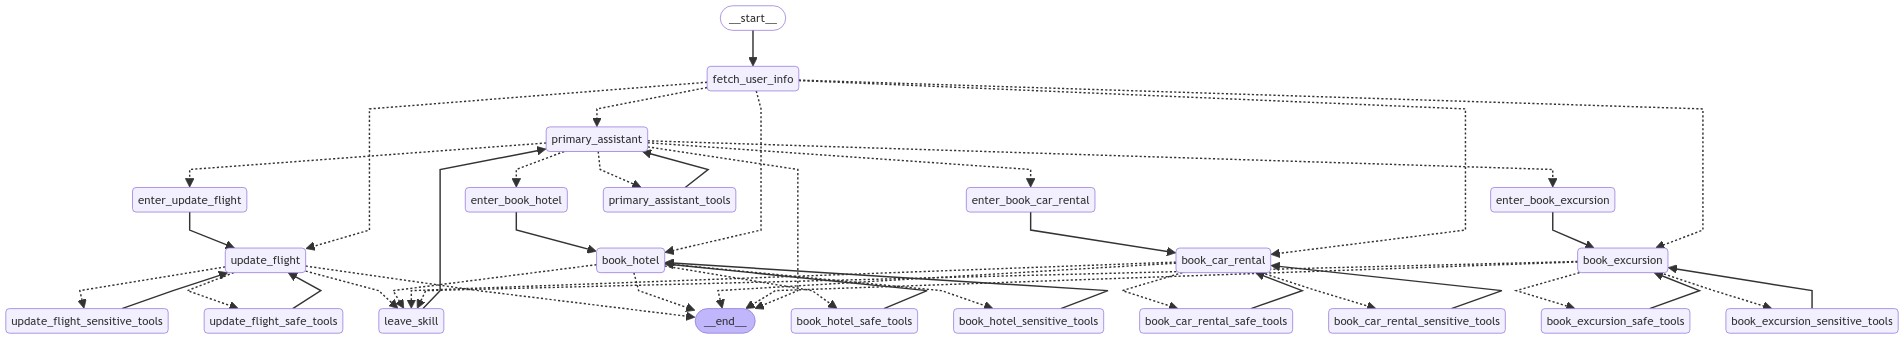

In [28]:
from IPython.display import Image, display

try:
    display(Image(part_4_graph.get_graph(xray=True).draw_mermaid_png()))
except Exception:
    pass

### Example Conversation

In [34]:
import shutil
import uuid

# 创建一个对话示例，模拟用户可能与助手进行的交流
tutorial_questions = [
    "你好，我的航班是什么时候？",
    "我可以将航班改到更早的时间吗？我想今天晚些时候离开。",
    "那就把我的航班改到下周的某个时间。",
    "下一个可用的选项就行。",
    "住宿呢？", # 住宿和交通呢？
    "我想找一家价格适中的酒店，要住一周（7天）。",  # 我想找一家价格适中的酒店，要住一周（7天）。还需要租一辆车。
    "好的，你能为我预订你推荐的酒店吗？听起来不错。",
    "是的，请预订任何价格适中且有空房的选项。",
    "现在来说说租车，我有哪些选择？",
    "太好了，就选最便宜的选项吧。请预订7天。",
    "那么接下来有什么旅行建议吗？",
    "我在那里的时候，这些活动还有吗？",
    "有意思——我喜欢博物馆，有哪些选择？",
    "好的，选一个在我到达后的第二天预订。",
]

# 使用备份文件更新数据库，以便每次从原始状态重新开始
shutil.copy(backup_file, db)
thread_id = str(uuid.uuid4())

config = {
    "configurable": {
        # passenger_id 用于我们的航班工具中
        # 以获取用户的航班信息
        "passenger_id": "3442 587242",
        # 检查点通过 thread_id 访问
        "thread_id": thread_id,
    }
}

_printed = set()
for question in tutorial_questions:
    events = part_4_graph.stream(
        {"messages": ("user", question)}, config, stream_mode="values"
    )
    for event in events:
        _print_event(event, _printed)
    snapshot = part_4_graph.get_state(config)
    while snapshot.next:
        # 我们有一个中断！agent 正在尝试使用一个工具，用户可以批准或拒绝它
        # 注意：此代码全部在您的图之外。通常，您会将输出流式传输到 UI。
        # 然后，当用户提供输入时，您将让前端通过 API 调用触发新的运行。
        user_input = input(
            "你是否同意上述操作？输入‘y’继续；"
            "否则，请解释你请求的更改。\n\n"
        )
        if user_input.strip() == "y":
            # 继续执行
            result = part_4_graph.invoke(
                None,
                config,
            )
        else:
            # 通过以下方式满足工具调用要求
            # 提供有关所请求的更改/改变主意的说明
            result = part_4_graph.invoke(
                {
                    "messages": [
                        ToolMessage(
                            tool_call_id=event["messages"][-1].tool_calls[0]["id"],
                            content=f"API 调用被用户拒绝。理由：'{user_input}'。继续协助，考虑用户的输入。",
                        )
                    ]
                },
                config,
            )
        snapshot = part_4_graph.get_state(config)

================================ Human Message =================================

你好，我的航班是什么时候？
================================== Ai Message ==================================

您的航班，航班号 LX0112，计划于2024年8月1日从巴黎戴高乐机场 (CDG) 出发，时间为19:42，并计划于同日21:12抵达巴塞尔机场 (BSL)。您的座位号是18E，属于经济舱。如需更多帮助，请随时告诉我！
================================ Human Message =================================

我可以将航班改到更早的时间吗？我想今天晚些时候离开。
================================== Ai Message ==================================
Tool Calls:
  lookup_policy (call_HoUDZSri3eZHlxQFoIW6kfyK)
 Call ID: call_HoUDZSri3eZHlxQFoIW6kfyK
  Args:
    query: flight change
================================= Tool Message =================================
Name: lookup_policy


## Booking and Cancellation

1. How can I change my booking?
	* The ticket number must start with 724 (SWISS ticket no./plate).
	* The ticket was not paid for by barter or voucher (there are exceptions to voucher payments; if the ticket was paid for in full by voucher, then it may be 

你是否同意上述操作？输入‘y’继续；否则，请解释你请求的更改。

 y


当前处于:  update_flight
================================ Human Message =================================

住宿呢？
当前处于:  update_flight
当前处于:  update_flight
================================== Ai Message ==================================
Tool Calls:
  CompleteOrEscalate (call_PcmFa5jrXi2EcAPpW5PxNLyW)
 Call ID: call_PcmFa5jrXi2EcAPpW5PxNLyW
  Args:
    reason: The user is requesting assistance with accommodation, which is outside of my operational scope. Please escalate to the main assistant.
================================= Tool Message =================================

恢复与主助手的对话。请反思过去的对话并根据需要协助用户。
================================== Ai Message ==================================
Tool Calls:
  ToHotelBookingAssistant (call_GtEzPOPJrU7RghadeXDxYZUX)
 Call ID: call_GtEzPOPJrU7RghadeXDxYZUX
  Args:
    location: Basel
    checkin_date: 2024-08-07
    checkout_date: 2024-08-08
    request: Please book a hotel for one night.
当前处于:  book_hotel
================================= Tool Message =======

你是否同意上述操作？输入‘y’继续；否则，请解释你请求的更改。

 y


当前处于:  book_hotel
================================ Human Message =================================

是的，请预订任何价格适中且有空房的选项。
当前处于:  book_hotel
当前处于:  book_hotel
================================== Ai Message ==================================
Tool Calls:
  book_hotel (call_2uT6hIstdrKtxZnM51cCVcYw)
 Call ID: call_2uT6hIstdrKtxZnM51cCVcYw
  Args:
    hotel_id: 8


你是否同意上述操作？输入‘y’继续；否则，请解释你请求的更改。

 不需要重复预订了


当前处于:  book_hotel
================================ Human Message =================================

现在来说说租车，我有哪些选择？
当前处于:  book_hotel
当前处于:  book_hotel
================================== Ai Message ==================================
Tool Calls:
  CompleteOrEscalate (call_8kES5fMntPkI6C9nTrzmLRq8)
 Call ID: call_8kES5fMntPkI6C9nTrzmLRq8
  Args:
    reason: The user is asking about car rental options, which is outside of my specific task capabilities. Please escalate to the main assistant.
================================= Tool Message =================================

恢复与主助手的对话。请反思过去的对话并根据需要协助用户。
================================== Ai Message ==================================
Tool Calls:
  ToBookCarRental (call_9k18WvQCoBpa05RVcmvWptaC)
 Call ID: call_9k18WvQCoBpa05RVcmvWptaC
  Args:
    location: Basel
    start_date: 2024-08-07
    end_date: 2024-08-14
    request: I need a car rental for one week in Basel from August 7 to August 14, 2024. Please provide me with the available options

你是否同意上述操作？输入‘y’继续；否则，请解释你请求的更改。

 y


当前处于:  book_car_rental
================================ Human Message =================================

那么接下来有什么旅行建议吗？
当前处于:  book_car_rental
当前处于:  book_car_rental
================================== Ai Message ==================================
Tool Calls:
  CompleteOrEscalate (call_1IrgGBX4RjTjHCjwSwMX1AfN)
 Call ID: call_1IrgGBX4RjTjHCjwSwMX1AfN
  Args:
    reason: The user is asking for travel advice, which is outside of my specific task capabilities. Please escalate to the main assistant.
================================= Tool Message =================================

恢复与主助手的对话。请反思过去的对话并根据需要协助用户。
================================== Ai Message ==================================
Tool Calls:
  ToBookExcursion (call_5b1azvsOURRO8mHwR9txrOxz)
 Call ID: call_5b1azvsOURRO8mHwR9txrOxz
  Args:
    location: Basel
    request: I need travel recommendations for Basel during my stay from August 7 to August 14, 2024.
当前处于:  book_excursion
================================= Tool Message =======

你是否同意上述操作？输入‘y’继续；否则，请解释你请求的更改。

 y


In [35]:
for snapshot in part_4_graph.get_state_history(config):
    print(snapshot)
    print()

StateSnapshot(values={'messages': [HumanMessage(content='你好，我的航班是什么时候？', id='8854aa8b-48dd-42b1-91a2-743a48fe1137'), AIMessage(content='您的航班，航班号 LX0112，计划于2024年8月1日从巴黎戴高乐机场 (CDG) 出发，时间为19:42，并计划于同日21:12抵达巴塞尔机场 (BSL)。您的座位号是18E，属于经济舱。如需更多帮助，请随时告诉我！', response_metadata={'token_usage': {'completion_tokens': 114, 'prompt_tokens': 1144, 'total_tokens': 1258}, 'model_name': 'gpt-4-turbo', 'system_fingerprint': 'fp_3a478acf5e', 'finish_reason': 'stop', 'logprobs': None}, id='run-37d05de9-eaeb-4140-a785-9d5935c0bdba-0'), HumanMessage(content='我可以将航班改到更早的时间吗？我想今天晚些时候离开。', id='f740784b-a970-4e04-ac40-adf8fec7888b'), AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'call_HoUDZSri3eZHlxQFoIW6kfyK', 'function': {'arguments': '{"query":"flight change"}', 'name': 'lookup_policy'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 1297, 'total_tokens': 1312}, 'model_name': 'gpt-4-turbo', 'system_fingerprint': 'fp_c77e07d4ef', 'finish_reaso

[我的 LangSmith 跟踪](https://smith.langchain.com/public/e7a5f015-157c-428d-a80f-c18efe14f8fa/r)

### 失败的运行

In [29]:
import shutil
import uuid

# 创建一个对话示例，模拟用户可能与助手进行的交流
tutorial_questions = [
    "你好，我的航班是什么时候？",
    "我可以将航班改到更早的时间吗？我想今天晚些时候离开。",
    "那就把我的航班改到下周的某个时间。",
    "下一个可用的选项就行。",
    "住宿和交通呢？",
    "我想找一家价格适中的酒店，要住一周（7天）。还需要租一辆车。",
    "好的，你能为我预订你推荐的酒店吗？听起来不错。",
    "是的，请预订任何价格适中且有空房的选项。",
    "现在来说说租车，我有哪些选择？",
    "太好了，就选最便宜的选项吧。请预订7天。",
    "那么接下来有什么旅行建议吗？",
    "我在那里的时候，这些活动还有吗？",
    "有意思——我喜欢博物馆，有哪些选择？",
    "好的，选一个在我到达后的第二天预订。",
]

# 使用备份文件更新数据库，以便每次从原始状态重新开始
shutil.copy(backup_file, db)
thread_id = str(uuid.uuid4())

config = {
    "configurable": {
        # passenger_id 用于我们的航班工具中
        # 以获取用户的航班信息
        "passenger_id": "3442 587242",
        # 检查点通过 thread_id 访问
        "thread_id": thread_id,
    }
}

_printed = set()
for question in tutorial_questions:
    events = part_4_graph.stream(
        {"messages": ("user", question)}, config, stream_mode="values"
    )
    for event in events:
        _print_event(event, _printed)
    snapshot = part_4_graph.get_state(config)
    while snapshot.next:
        # 我们有一个中断！agent 正在尝试使用一个工具，用户可以批准或拒绝它
        # 注意：此代码全部在您的图之外。通常，您会将输出流式传输到 UI。
        # 然后，当用户提供输入时，您将让前端通过 API 调用触发新的运行。
        user_input = input(
            "你是否同意上述操作？输入‘y’继续；"
            "否则，请解释你请求的更改。\n\n"
        )
        if user_input.strip() == "y":
            # 继续执行
            result = part_4_graph.invoke(
                None,
                config,
            )
        else:
            # 通过以下方式满足工具调用要求
            # 提供有关所请求的更改/改变主意的说明
            result = part_4_graph.invoke(
                {
                    "messages": [
                        ToolMessage(
                            tool_call_id=event["messages"][-1].tool_calls[0]["id"],
                            content=f"API 调用被用户拒绝。理由：'{user_input}'。继续协助，考虑用户的输入。",
                        )
                    ]
                },
                config,
            )
        snapshot = part_4_graph.get_state(config)

================================ Human Message =================================

你好，我的航班是什么时候？
================================== Ai Message ==================================

您的航班是 Swiss International Air Lines 航班号 LX0112，从巴黎查尔斯·戴高乐机场 (CDG) 到巴塞尔 (BSL)。预计出发时间为2024年8月1日19:42，预计到达时间为2024年8月1日21:12。您的座位号是18E，舱位为经济舱。如果您需要进一步的帮助，请告诉我！
================================ Human Message =================================

我可以将航班改到更早的时间吗？我想今天晚些时候离开。
================================== Ai Message ==================================
Tool Calls:
  lookup_policy (call_dcXUjFiJ7dGn4TIJnILeodJS)
 Call ID: call_dcXUjFiJ7dGn4TIJnILeodJS
  Args:
    query: flight change
================================= Tool Message =================================
Name: lookup_policy


## Booking and Cancellation

1. How can I change my booking?
	* The ticket number must start with 724 (SWISS ticket no./plate).
	* The ticket was not paid for by barter or voucher (there are exceptions to voucher payments; if the ticket was

你是否同意上述操作？输入‘y’继续；否则，请解释你请求的更改。

 y


当前处于:  update_flight
================================ Human Message =================================

住宿和交通呢？
当前处于:  update_flight
当前处于:  update_flight
================================== Ai Message ==================================
Tool Calls:
  CompleteOrEscalate (call_vqigy02TnN4znsKGuBhMnlow)
 Call ID: call_vqigy02TnN4znsKGuBhMnlow
  Args:
    reason: 用户请求关于住宿和交通的帮助，这超出了我的功能范围。
================================= Tool Message =================================

恢复与主助手的对话。请反思过去的对话并根据需要协助用户。
================================== Ai Message ==================================
Tool Calls:
  ToHotelBookingAssistant (call_nWa3snXy3Snx06YqLWbNe8Da)
 Call ID: call_nWa3snXy3Snx06YqLWbNe8Da
  Args:
    location: Basel
    checkin_date: 2024-08-12
    checkout_date: 2024-08-13
    request: Please book a hotel for one night, close to the city center with good public transportation access.
  ToBookCarRental (call_DQAfVJZ4L2QpvXF3HoKVQrqE)
 Call ID: call_DQAfVJZ4L2QpvXF3HoKVQrqE
  Args:
    location: 

BadRequestError: Error code: 400 - {'error': {'message': "An assistant message with 'tool_calls' must be followed by tool messages responding to each 'tool_call_id'. The following tool_call_ids did not have response messages: call_DQAfVJZ4L2QpvXF3HoKVQrqE", 'type': 'invalid_request_error', 'param': 'messages', 'code': None}}

- 这里出错是因为当前我们的程序，不支持并行调用工具，一次只调用一个工具。

In [31]:
for snapshot in part_4_graph.get_state_history(config):
    print(snapshot)
    print()

StateSnapshot(values={'messages': [HumanMessage(content='你好，我的航班是什么时候？', id='c674cedb-2c21-4891-9df5-4991db593ab1'), AIMessage(content='您的航班是 Swiss International Air Lines 航班号 LX0112，从巴黎查尔斯·戴高乐机场 (CDG) 到巴塞尔 (BSL)。预计出发时间为2024年8月1日19:42，预计到达时间为2024年8月1日21:12。您的座位号是18E，舱位为经济舱。如果您需要进一步的帮助，请告诉我！', response_metadata={'token_usage': {'completion_tokens': 126, 'prompt_tokens': 1144, 'total_tokens': 1270}, 'model_name': 'gpt-4-turbo', 'system_fingerprint': 'fp_c77e07d4ef', 'finish_reason': 'stop', 'logprobs': None}, id='run-013f57af-9116-4517-ab9e-d4bac612480a-0'), HumanMessage(content='我可以将航班改到更早的时间吗？我想今天晚些时候离开。', id='6503d5c9-a2db-4539-adcd-94067a0a535e'), AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'call_dcXUjFiJ7dGn4TIJnILeodJS', 'function': {'arguments': '{"query":"flight change"}', 'name': 'lookup_policy'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 1309, 'total_tokens': 1324}, 'model_name': 'gpt-4-turbo', 'system